# Phase 2.4 — Financial Feature Analysis

**Stock Movement Prediction & ML-Based Trading Strategy Backtesting — HPG.** Nghiên cứu 26 feature từ `data/processed/HPG_features_labeled.parquet`; dữ liệu daily 2016–2026. RQ1 dự báo Close(t+1) > Close(t), với X được biết sau Close(t). RQ2 kiểm tra khả năng chuyển dự báo thành chiến lược sau chi phí trong giai đoạn sau.

Pipeline: Raw OHLCV → Feature Engineering → Label Engineering → Dataset Assembly → **Feature Analysis** → Walk-forward Modeling → Backtesting. Notebook khảo sát chất lượng, phân phối, trùng lặp, liên hệ với return tương lai và tính ổn định. Đây là nghiên cứu mô tả, không huấn luyện model, không kiểm định alpha và không chứng minh lợi nhuận. Tập test được giữ kín với mọi phép phân tích nhãn.

## 1. Đọc và kiểm tra dataset

Kiểm tra schema, thứ tự thời gian, metadata, kiểu và Inf trước khi phân tích giúp tránh nhầm thông tin tương lai vào X. Master giữ tất cả phiên và NaN; eligible view chỉ giữ hàng đủ feature và nhãn. Kiểm tra nhãn ở đây chỉ áp dụng train/validation, không xem phân phối hay giá trị target test.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# Tìm root bằng cách đi lên từ cwd hoặc từ các thư mục cha, không dùng đường dẫn cá nhân.
def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base/'configs/config.yaml').is_file() and (base/'src/dataset_builder.py').is_file(): return base
    raise RuntimeError('Chạy notebook từ repository hoặc một thư mục con của repository')
ROOT=find_root(); sys.path.insert(0,str(ROOT))
from src.dataset_builder import load_project_config, expected_feature_columns, LABEL_COLUMNS
from src.features import OHLCV, validate_ohlcv
cfg=load_project_config(ROOT/'configs/config.yaml')
df=pd.read_parquet(ROOT/cfg['data']['processed_path']); names=df.attrs['feature_columns']; labels=df.attrs['label_columns']
assert isinstance(df.index,pd.DatetimeIndex) and not df.index.hasnans and df.index.is_unique and df.index.is_monotonic_increasing
assert df.columns.is_unique and list(df.columns)==list(OHLCV)+names+LABEL_COLUMNS
assert names==expected_feature_columns(cfg) and labels==LABEL_COLUMNS and len(names)==26 and len(labels)==6
assert df.attrs['schema_version']==1 and df.attrs['fixed_holding_sessions']==cfg['labeling']['fixed_holding_sessions']
validate_ohlcv(df.loc[:,list(OHLCV)])
assert all(str(df[c].dtype)=='Int8' for c in labels if c.startswith('target_'))
# Không tính thống kê target của tập test: chỉ metadata/dtype, chỉ kiểm tra Inf trên features.
assert not np.isinf(df[names].to_numpy(dtype=float)).any()
figdir=ROOT/'results'/'figures'/'notebook_02'; figdir.mkdir(exist_ok=True,parents=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.max_rows',100); pd.set_option('display.max_columns',30)
research_notes={}
summary=pd.DataFrame({'Mục':['Số hàng','Số cột','OHLCV','Feature','Forward/target','Ngày đầu','Ngày cuối','Index','Inf trong features'], 'Giá trị':[len(df),len(df.columns),len(OHLCV),len(names),len(labels),str(df.index.min().date()),str(df.index.max().date()),'unique, tăng dần','0']})
display(summary); display(df.dtypes.to_frame('dtype'))
research_notes['schema']=f"Master có {len(df):,} hàng, {len(df.columns)} cột, gồm {len(OHLCV)} OHLCV, {len(names)} features và {len(labels)} cột forward/target; index từ {df.index.min().date()} đến {df.index.max().date()}, duy nhất và tăng. Dtype nhãn nullable Int8, không có Inf trong features. Điều này kiểm tra cấu trúc, không chứng minh chất lượng nguồn hay tính point-in-time."

,Mục,Giá trị
0,Số hàng,2639
1,Số cột,37
2,OHLCV,5
3,Feature,26
4,Forward/target,6
5,Ngày đầu,2016-01-04
6,Ngày cuối,2026-10-30
7,Index,"unique, tăng dần"
8,Inf trong features,0


,dtype
Price,
open,float64
high,float64
low,float64
close,float64
volume,int64
log_return,float64
return_lag_1,float64
return_lag_2,float64
return_lag_3,float64


**Diễn giải từ kết quả:** Master có 2,639 hàng, 37 cột, gồm 5 OHLCV, 26 features và 6 cột forward/target; index từ 2016-01-04 đến 2026-10-30, duy nhất và tăng. Dtype nhãn nullable Int8, không có Inf trong features. Điều này kiểm tra cấu trúc, không chứng minh chất lượng nguồn hay tính point-in-time.

## 2. Temporal research split và purge theo horizon

Đường biên dựa ngày giao dịch thực tế: năm đầu + 5 năm train, tiếp theo 12 tháng validation, còn lại test. Với tín hiệu t, nhãn RQ1 kết thúc tại t+1 và RQ2 tại t+1+h. Loại hàng có thời điểm kết thúc ở hoặc sau ngày đầu kỳ kế tiếp. Không áp dụng thêm embargo 5 phiên: nó là tham số cấu hình cho validation sau này, khác purge theo label; phương án này không phải production walk-forward splitter.

,Giai đoạn,Đầu,Cuối,Rows,Đủ feature,RQ1 eligible,RQ2 eligible,Purge RQ1,Purge RQ2
0,Train,2016-01-04,2020-12-31,1223,1024,1023,1020,1,4
1,Validation,2021-01-04,2021-12-31,224,224,223,220,1,4
2,Reserved test,2022-01-04,2026-10-30,1192,không đánh giá,kín,kín,—,—


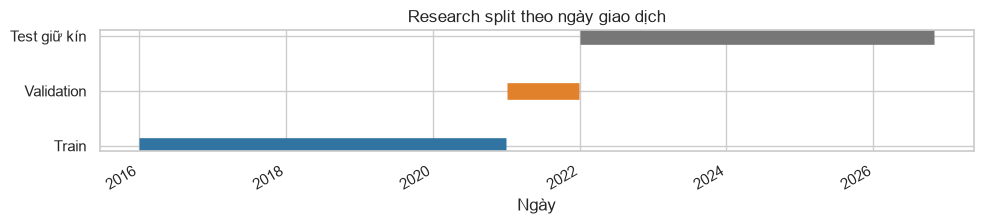

In [2]:
start_year=df.index.min().year
val_start=pd.Timestamp(start_year+cfg['validation']['initial_train_years'],1,1)
test_start=val_start+pd.DateOffset(months=cfg['validation']['val_months'])
train=df.loc[df.index<val_start].copy(); val=df.loc[(df.index>=val_start)&(df.index<test_start)].copy()
# Chỉ lấy index của test để xác định biên; không đọc target test.
test_index=df.index[df.index>=test_start]
assert len(train)>0 and len(val)>0 and len(test_index)>0
actual_val=val.index[0]; actual_test=test_index[0]
positions=pd.Series(df.index,index=df.index)
end1=positions.shift(-1); end4=positions.shift(-(1+cfg['labeling']['fixed_holding_sessions']))
complete=df[names].notna().all(axis=1)
def eligible(part,boundary,end,label):
    idx=part.index; ends=end.loc[idx]; keep=(ends<boundary)&part[label].notna()&complete.loc[idx]
    assert (ends.loc[keep]<boundary).all()
    return part.loc[keep].copy()
tr1=eligible(train,actual_val,end1,'target_direction'); va1=eligible(val,actual_test,end1,'target_direction')
tr2=eligible(train,actual_val,end4,'target_fixed_hold_net_proxy'); va2=eligible(val,actual_test,end4,'target_fixed_hold_net_proxy')
# Chỉ kiểm tra Inf và class cho các khoảng được phép.
for part in (tr1,va1,tr2,va2):
    assert not np.isinf(part[labels].select_dtypes(include='number').to_numpy(dtype=float,na_value=np.nan)).any()
    for c in [x for x in labels if x.startswith('target_')]: assert part[c].dropna().isin([0,1]).all()
period_rows=[]
for label,part,boundary,a,b in [('Train',train,actual_val,tr1,tr2),('Validation',val,actual_test,va1,va2)]:
    period_rows.append([label,str(part.index.min().date()),str(part.index.max().date()),len(part),int(complete.loc[part.index].sum()),len(a),len(b),int((end1.loc[part.index]>=boundary).sum()),int((end4.loc[part.index]>=boundary).sum())])
period_rows.append(['Reserved test',str(test_index.min().date()),str(test_index.max().date()),len(test_index),'không đánh giá','kín','kín','—','—'])
split=pd.DataFrame(period_rows,columns=['Giai đoạn','Đầu','Cuối','Rows','Đủ feature','RQ1 eligible','RQ2 eligible','Purge RQ1','Purge RQ2']); display(split)
fig,ax=plt.subplots(figsize=(10,2.4));
for y,(name,idx,color) in enumerate([('Train',train.index,'#3274a1'),('Validation',val.index,'#e1812c'),('Test giữ kín',test_index,'#777777')]):
    ax.plot([idx.min(),idx.max()],[y,y],lw=12,color=color,solid_capstyle='butt',label=name)
ax.set_yticks(range(3),['Train','Validation','Test giữ kín']); ax.set_title('Research split theo ngày giao dịch'); ax.set_xlabel('Ngày'); fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(figdir/'02_research_timeline.png',dpi=150); plt.show()
research_notes['split']=f"Train {train.index.min().date()}–{train.index.max().date()} có {len(train)} phiên; validation {val.index.min().date()}–{val.index.max().date()} có {len(val)}; test giữ kín {test_index.min().date()}–{test_index.max().date()} có {len(test_index)}. Sau warm-up và purge, RQ1 còn {len(tr1)}/{len(va1)} và RQ2 {len(tr2)}/{len(va2)} hàng train/validation. Số bị purge theo ranh giới lần lượt RQ1 {period_rows[0][7]}/{period_rows[1][7]}, RQ2 {period_rows[0][8]}/{period_rows[1][8]}. Không random shuffle; tính theo phiên thực, không phải ngày lịch."

**Diễn giải từ kết quả:** Train 2016-01-04–2020-12-31 có 1223 phiên; validation 2021-01-04–2021-12-31 có 224; test giữ kín 2022-01-04–2026-10-30 có 1192. Sau warm-up và purge, RQ1 còn 1023/223 và RQ2 1020/220 hàng train/validation. Số bị purge theo ranh giới lần lượt RQ1 1/1, RQ2 4/4. Không random shuffle; tính theo phiên thực, không phải ngày lịch.

## 3. Missing, ổn định số và dữ liệu volume

Phân tích feature trên train và validation để phân biệt warm-up với tỷ số không xác định; không fillna hay thay master. Missing sau lần hợp lệ đầu có thể là trường hợp số học hoặc dữ liệu cần điều tra. Thống kê cực trị có thể làm méo tương quan và mô hình tuyến tính.

,missing,missing_pct,first_valid,missing_after_first
Price,,,,
sma_ratio_200,199,13.752592,2016-10-21,0
volatility_63,63,4.353836,2016-04-07,0
sma_ratio_50,49,3.386317,2016-03-18,0
macd_ratio,25,1.727713,2016-02-15,0
ema_ratio_26,25,1.727713,2016-02-15,0
return_lag_21,22,1.520387,2016-02-03,0
momentum_21,21,1.451279,2016-02-02,0
volatility_21,21,1.451279,2016-02-02,0
sma_ratio_20,19,1.313062,2016-01-29,0


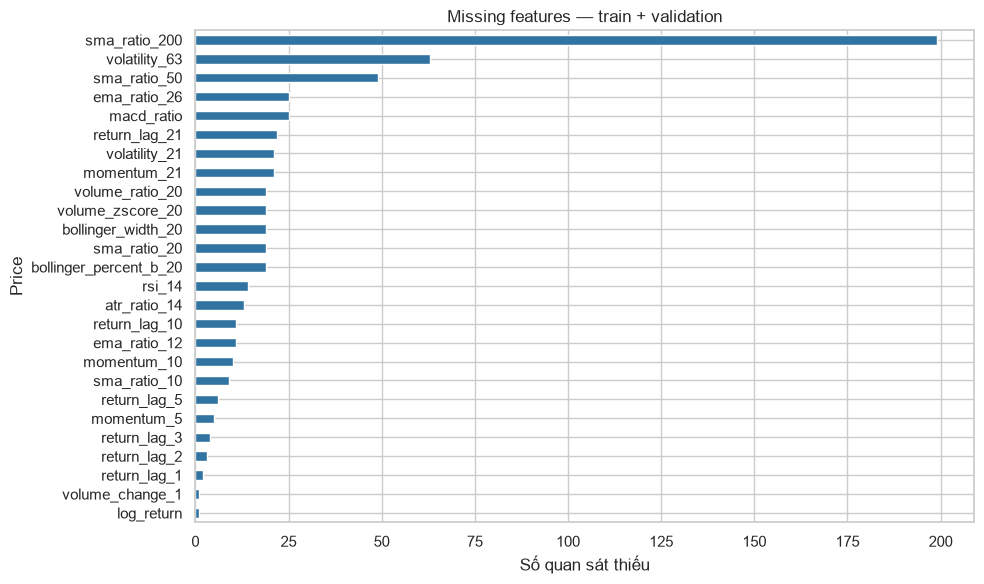

Price,volume,volume_change_1,volume_zscore_20,volume_ratio_20
date,,,,
2021-10-04,7610,-0.999868,-0.298051,0.000039
2021-10-05,50156363,6589.849277,-0.222141,0.254984


In [3]:
research=pd.concat([train[names],val[names]])
missing=pd.DataFrame({'missing':research.isna().sum(),'missing_pct':100*research.isna().mean(),'first_valid':research.apply(lambda x: x.first_valid_index()),'missing_after_first':research.apply(lambda x: x.loc[x.first_valid_index():].isna().sum() if x.first_valid_index() is not None else x.isna().sum())}).sort_values('missing',ascending=False)
display(missing)
fig,ax=plt.subplots(figsize=(10,6)); missing['missing'].sort_values().plot.barh(ax=ax,color='#3274a1'); ax.set(xlabel='Số quan sát thiếu',title='Missing features — train + validation'); fig.tight_layout(); fig.savefig(figdir/'02_feature_missing_values.png',dpi=150); plt.show()
anomaly=val.loc['2021-10-04':'2021-10-05',['volume','volume_change_1','volume_zscore_20','volume_ratio_20']]; display(anomaly)
topmiss=missing.index[0]; post=int(missing.missing_after_first.sum()); d0=val.loc[pd.Timestamp('2021-10-04'),'volume']; d1=val.loc[pd.Timestamp('2021-10-05'),'volume']; change=val.loc[pd.Timestamp('2021-10-05'),'volume_change_1']
research_notes['quality']=f"Trong train+validation, {topmiss} thiếu nhiều nhất: {missing.loc[topmiss,'missing']} hàng ({missing.loc[topmiss,'missing_pct']:.2f}%), chủ yếu do warm-up; tổng missing sau lần hợp lệ đầu là {post}. Volume 04/10/2021 = {d0:,.0f}, phiên sau = {d1:,.0f}, volume_change_1 = {change:,.2f} lần, do mẫu số rất nhỏ. Đây là quan sát validation, không dùng để điều chỉnh giả thuyết train. Quan sát có thể ảnh hưởng rolling volume đến khi rời cửa sổ và Pearson; cần đối chiếu corporate actions/nguồn, không tự kết luận lỗi hoặc xóa. Giá điều chỉnh hồi tố có thể không point-in-time. Logistic Regression nhạy scale/cực trị; cây cũng có thể tạo split dựa trên số ít điểm."

**Diễn giải từ kết quả:** Trong train+validation, sma_ratio_200 thiếu nhiều nhất: 199 hàng (13.75%), chủ yếu do warm-up; tổng missing sau lần hợp lệ đầu là 0. Volume 04/10/2021 = 7,610, phiên sau = 50,156,363, volume_change_1 = 6,589.85 lần, do mẫu số rất nhỏ. Đây là quan sát validation, không dùng để điều chỉnh giả thuyết train. Quan sát có thể ảnh hưởng rolling volume đến khi rời cửa sổ và Pearson; cần đối chiếu corporate actions/nguồn, không tự kết luận lỗi hoặc xóa. Giá điều chỉnh hồi tố có thể không point-in-time. Logistic Regression nhạy scale/cực trị; cây cũng có thể tạo split dựa trên số ít điểm.

## 4. Phân phối 26 feature

Dùng train để phát triển giả thuyết. Histogram và boxplot hiển thị khoảng 1%–99% chỉ để nhìn rõ phần trung tâm; bảng vẫn dùng dữ liệu đầy đủ và hiển thị min/max, skewness, kurtosis dư. Không cắt hoặc sửa observations trong phép tính. Độ lệch và đuôi dài chỉ là mô tả, không phải kiểm định phân phối.

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis_excess,missing_pct
Price,,,,,,,,,,,,,
log_return,1222.0,0.00148,0.02021,-0.07246,-0.05274,-0.00929,0.00110,0.01198,0.05293,0.11430,0.03624,1.92694,0.08177
return_lag_1,1221.0,0.00147,0.02022,-0.07246,-0.05275,-0.00930,0.00109,0.01198,0.05293,0.11430,0.03752,1.92568,0.16353
return_lag_2,1220.0,0.00148,0.02022,-0.07246,-0.05275,-0.00925,0.00110,0.01198,0.05293,0.11430,0.03592,1.92770,0.24530
return_lag_3,1219.0,0.00148,0.02023,-0.07246,-0.05276,-0.00927,0.00109,0.01198,0.05293,0.11430,0.03587,1.92367,0.32706
return_lag_5,1217.0,0.00145,0.02023,-0.07246,-0.05278,-0.00930,0.00000,0.01191,0.05294,0.11430,0.03915,1.92781,0.49060
return_lag_10,1212.0,0.00141,0.02025,-0.07246,-0.05281,-0.00931,0.00000,0.01183,0.05294,0.11430,0.04327,1.92842,0.89943
return_lag_21,1201.0,0.00137,0.02023,-0.07246,-0.05290,-0.00930,0.00000,0.01183,0.05295,0.11430,0.04188,1.96721,1.79886
sma_ratio_10,1214.0,0.00707,0.03495,-0.11270,-0.08159,-0.01418,0.00766,0.02658,0.09993,0.14695,0.04470,1.07239,0.73590
sma_ratio_20,1204.0,0.01539,0.05317,-0.17798,-0.12007,-0.01695,0.01554,0.04743,0.15764,0.23282,0.07063,1.08504,1.55356


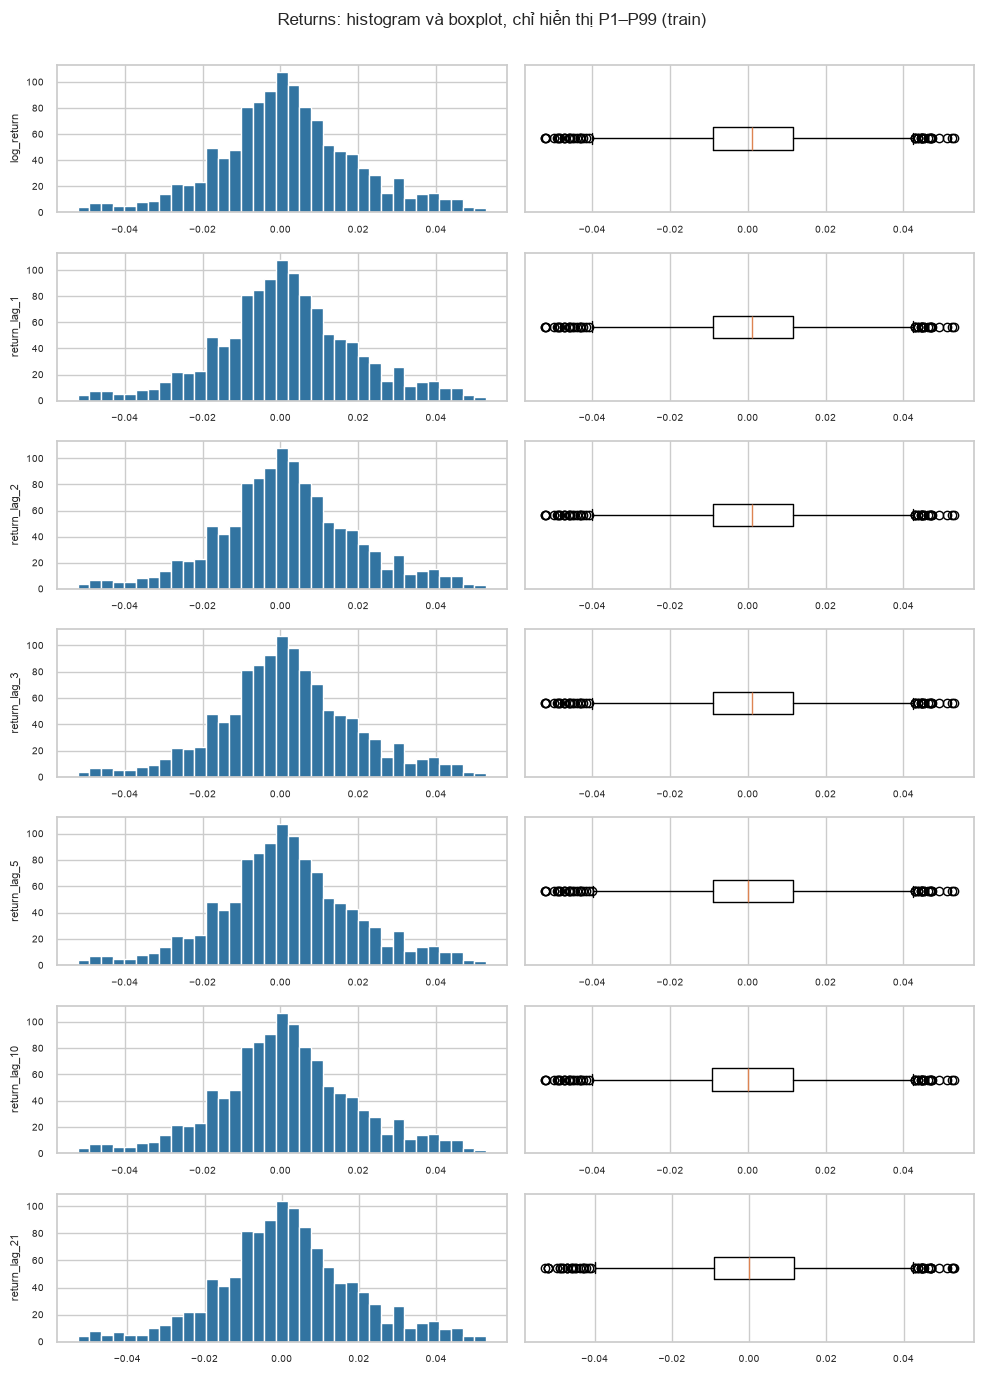

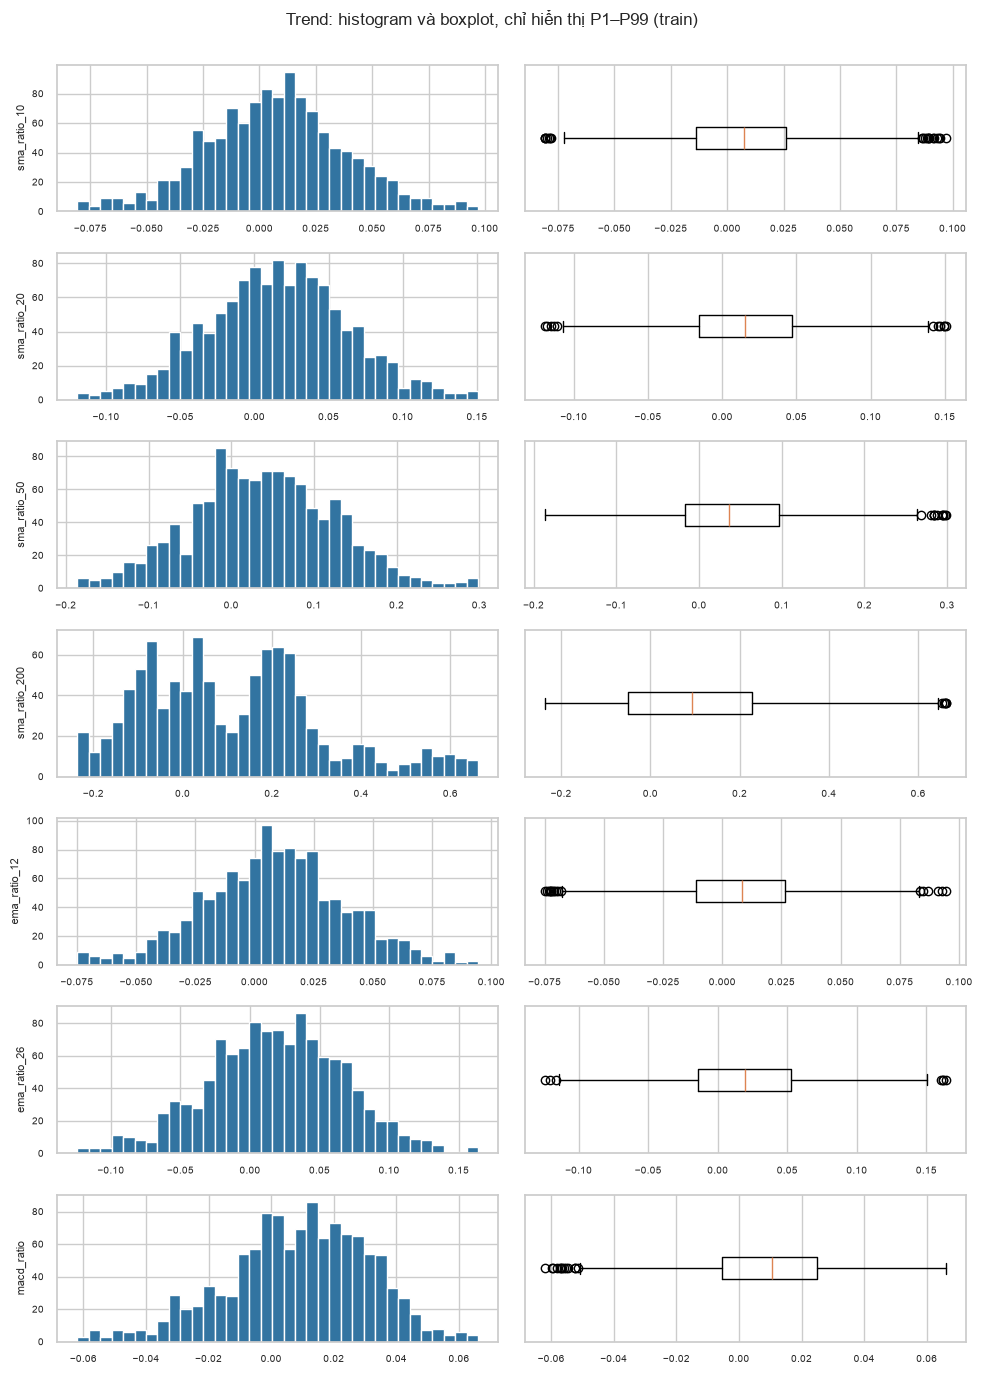

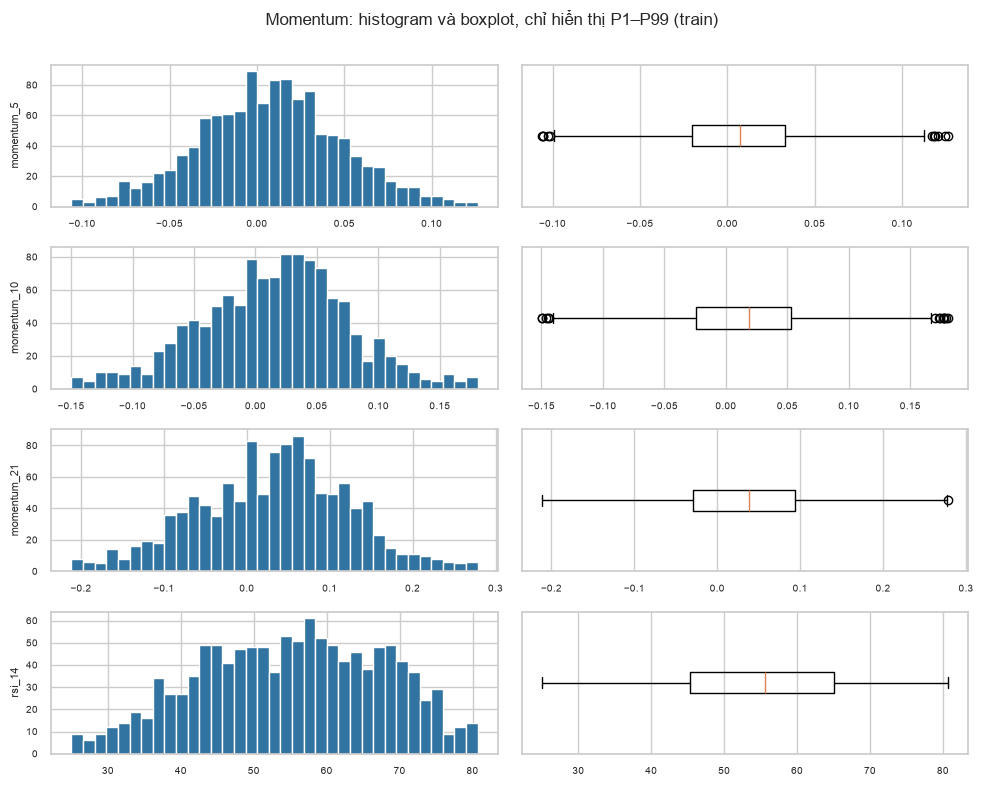

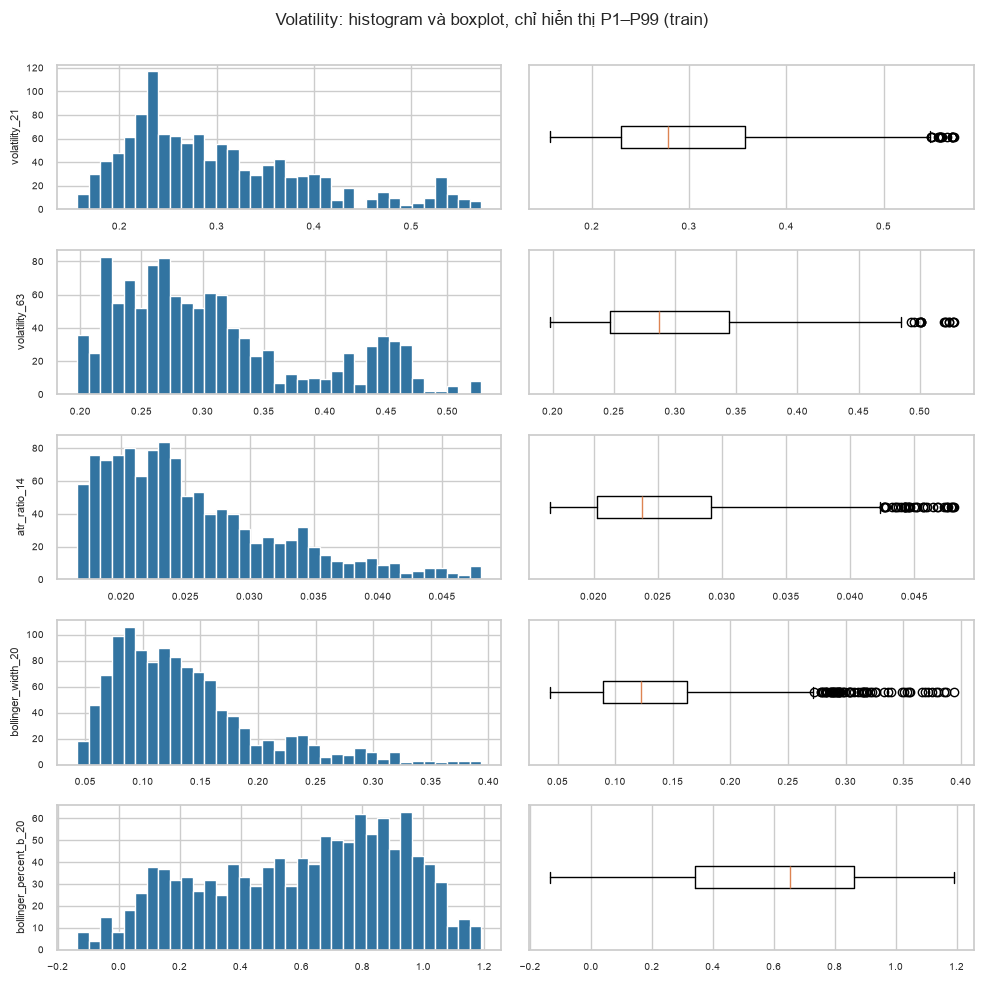

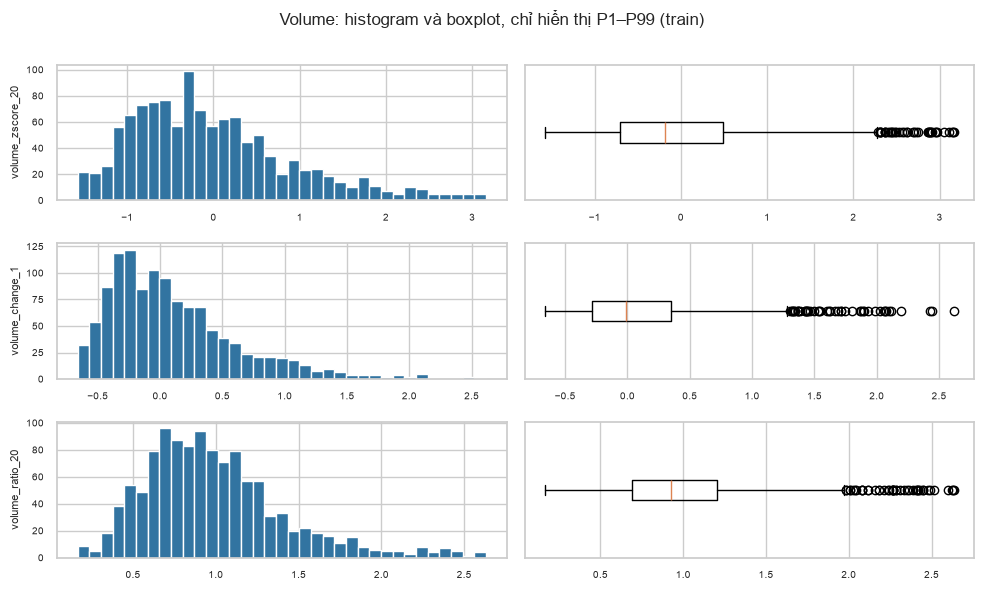

In [4]:
groups={'Returns':[x for x in names if x=='log_return' or x.startswith('return_lag_')], 'Trend':[x for x in names if x.startswith(('sma_ratio_','ema_ratio_')) or x=='macd_ratio'], 'Momentum':[x for x in names if x.startswith(('momentum_','rsi_'))], 'Volatility':[x for x in names if x.startswith(('volatility_','atr_ratio_','bollinger_'))], 'Volume':[x for x in names if x.startswith('volume_')]}
assert sum(map(len,groups.values()))==len(names) and set(sum(groups.values(),[]))==set(names)
category={f:g for g,fs in groups.items() for f in fs}
stats=train[names].describe(percentiles=[.01,.25,.5,.75,.99]).T
stats['skew']=train[names].skew(); stats['kurtosis_excess']=train[names].kurt(); stats['missing_pct']=100*train[names].isna().mean()
display(stats.round(5))
for group,fs in groups.items():
    fig,axes=plt.subplots(len(fs),2,figsize=(10,2.0*len(fs)),squeeze=False)
    for i,f in enumerate(fs):
        x=train[f].dropna(); lo,hi=x.quantile([.01,.99]); shown=x[(x>=lo)&(x<=hi)]
        axes[i,0].hist(shown,bins=35,color='#3274a1'); axes[i,0].set_ylabel(f,fontsize=8); axes[i,0].tick_params(labelsize=7)
        axes[i,1].boxplot(shown,orientation="horizontal",showfliers=True); axes[i,1].set_yticks([]); axes[i,1].tick_params(labelsize=7)
    fig.suptitle(f'{group}: histogram và boxplot, chỉ hiển thị P1–P99 (train)',fontsize=12); fig.tight_layout(rect=[0,0,1,.98]); fig.savefig(figdir/f'02_feature_distributions_{group.lower()}.png',dpi=150); plt.show()
log=train['log_return'].dropna(); rsi=train['rsi_14'].dropna(); v=train['volume_change_1'].dropna()
research_notes['distribution']=(f"Returns: log_return median {log.median():.5f}, P1/P99 {log.quantile(.01):.4f}/{log.quantile(.99):.4f}, skew {log.skew():.2f}, excess kurtosis {log.kurt():.2f}; đuôi và bất đối xứng là mô tả mẫu. Trend: sma_ratio_20 median {train.sma_ratio_20.median():.4f}, min/max {train.sma_ratio_20.min():.3f}/{train.sma_ratio_20.max():.3f}; horizon dài có thể phản ứng chậm hơn. Momentum: RSI median {rsi.median():.1f}, P25–P75 {rsi.quantile(.25):.1f}–{rsi.quantile(.75):.1f}; std momentum_5/21 = {train.momentum_5.std():.3f}/{train.momentum_21.std():.3f}. Volatility: volatility_21 median/max {train.volatility_21.median():.3f}/{train.volatility_21.max():.3f}, đỉnh ngày {train.volatility_21.idxmax().date()}; volatility_63 median/max {train.volatility_63.median():.3f}/{train.volatility_63.max():.3f}. Volume: volume_change_1 max {v.max():.3f}, P99 {v.quantile(.99):.3f}; volume_zscore_20 max {train.volume_zscore_20.max():.3f}. Biểu đồ cắt phạm vi hiển thị, không có nghĩa các cực trị đã bị loại khỏi thống kê.")

**Diễn giải từ kết quả:** Returns: log_return median 0.00110, P1/P99 -0.0527/0.0529, skew 0.04, excess kurtosis 1.93; đuôi và bất đối xứng là mô tả mẫu. Trend: sma_ratio_20 median 0.0155, min/max -0.178/0.233; horizon dài có thể phản ứng chậm hơn. Momentum: RSI median 55.5, P25–P75 45.0–65.4; std momentum_5/21 = 0.045/0.101. Volatility: volatility_21 median/max 0.278/0.641, đỉnh ngày 2020-04-07; volatility_63 median/max 0.287/0.553. Volume: volume_change_1 max 68.977, P99 2.637; volume_zscore_20 max 4.246. Biểu đồ cắt phạm vi hiển thị, không có nghĩa các cực trị đã bị loại khỏi thống kê.

## 5. Pearson và Spearman giữa các features

Hai ma trận dùng pairwise-complete train, Pearson cho tuyến tính và Spearman cho quan hệ đơn điệu theo thứ hạng. Ngưỡng |r| ≥ 0,90 chỉ là cảnh báo redundancy, không phải quy tắc loại feature. Mẫu khác nhau giữa cặp nếu thiếu; các cửa sổ giá có lịch sử chồng lấn.

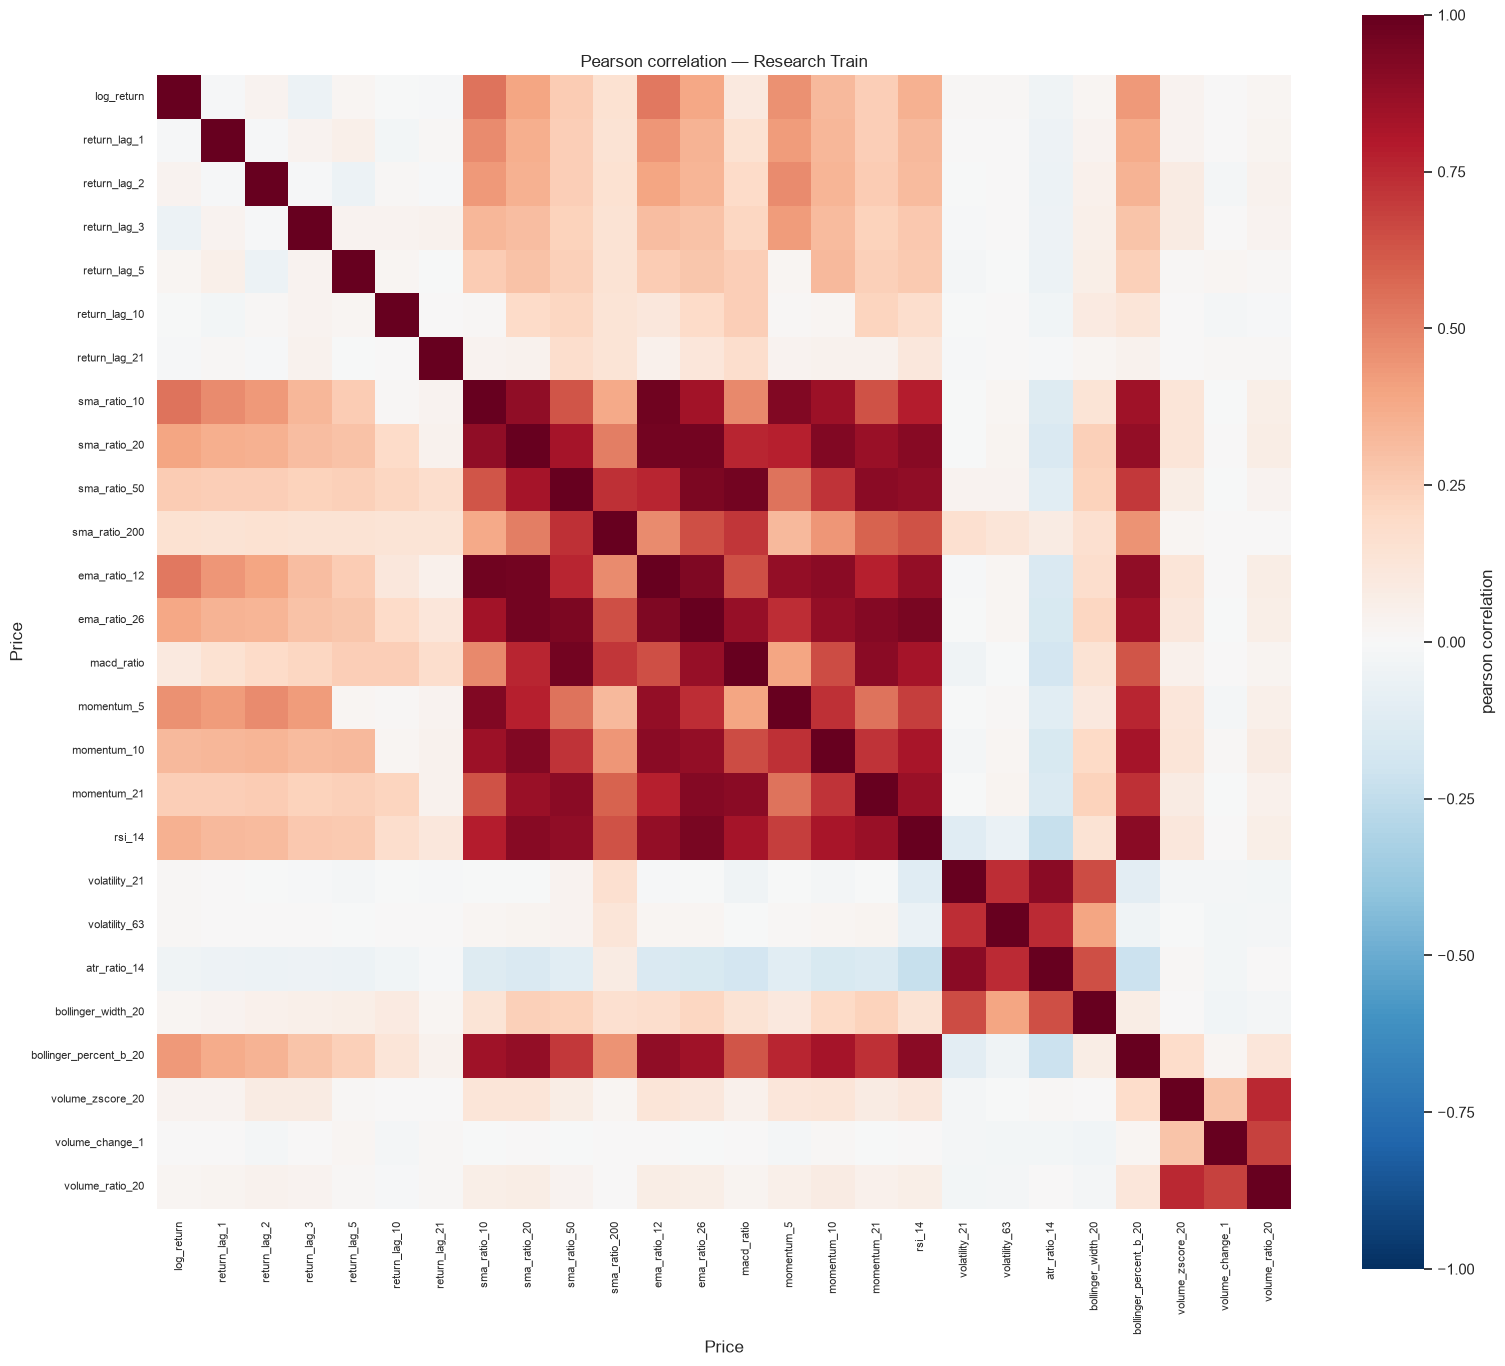

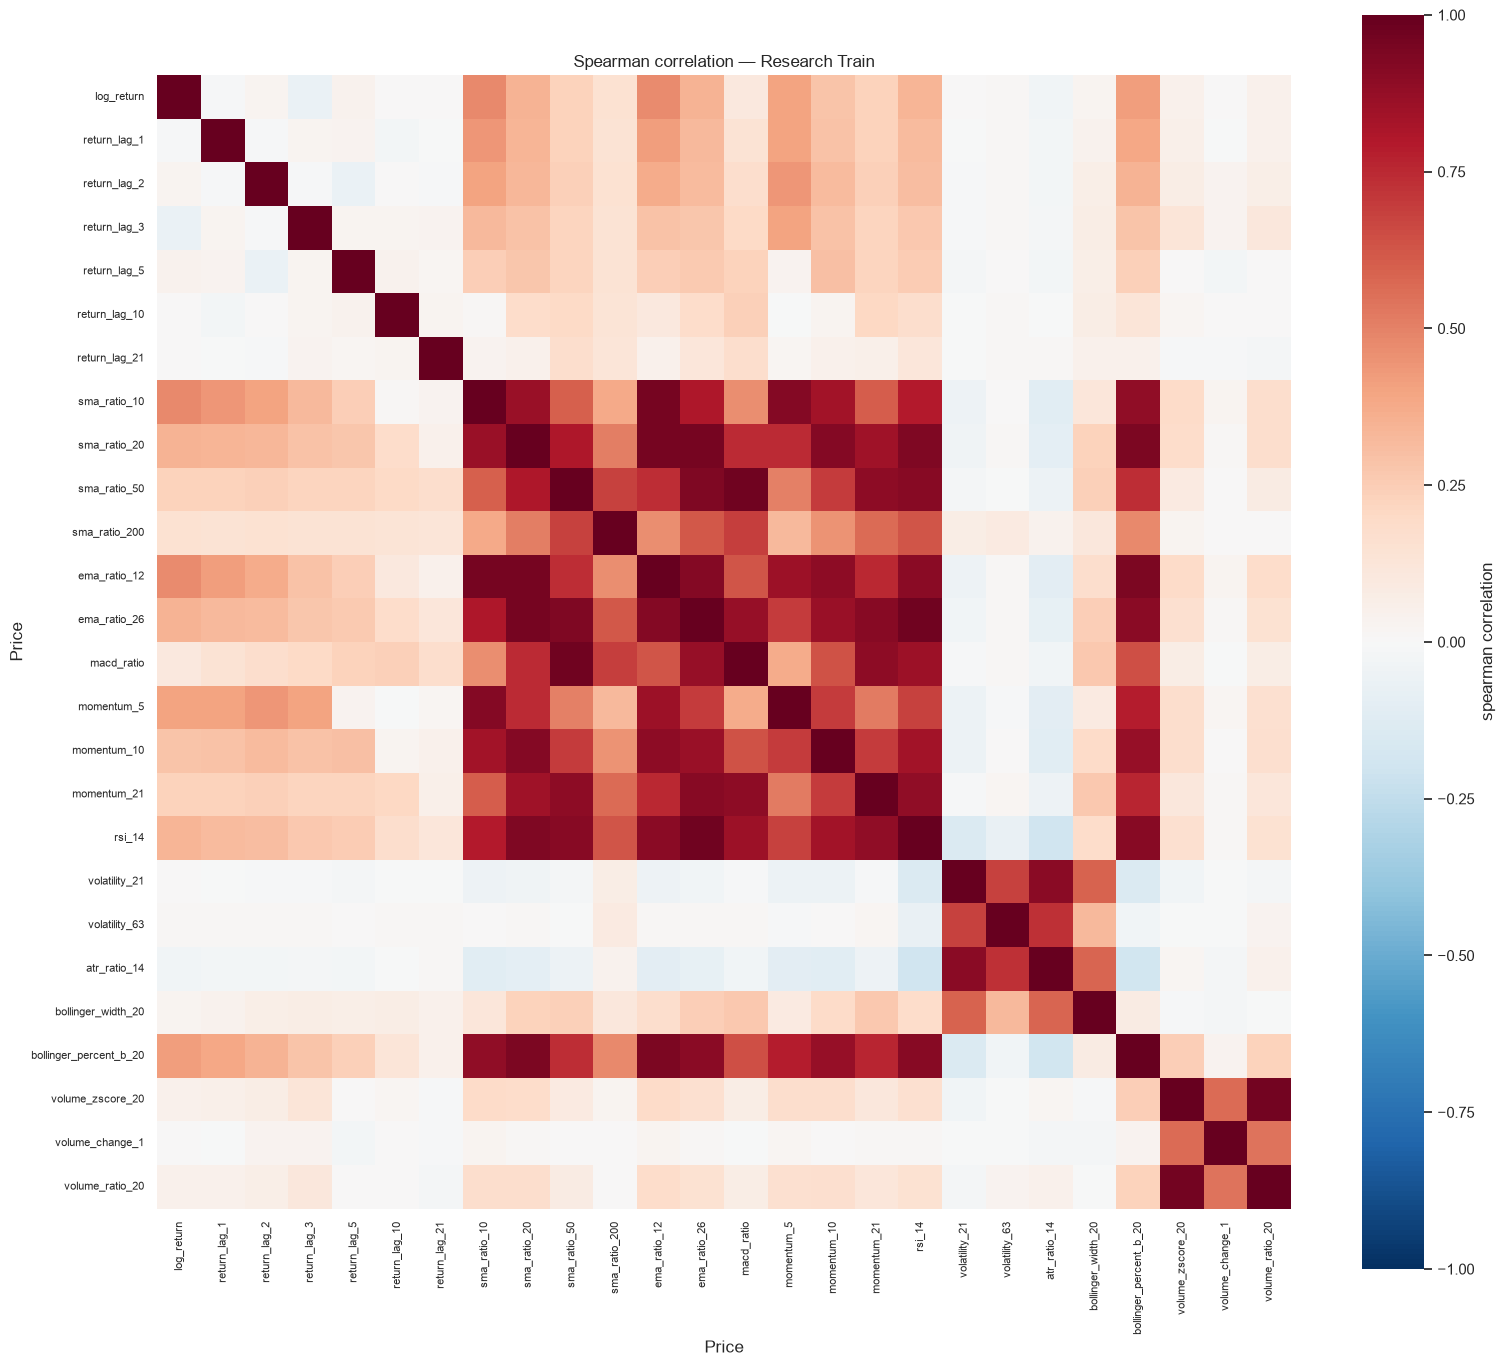

,A,B,Pearson,Spearman,Nhận xét
0,sma_ratio_10,ema_ratio_12,0.969426,0.960895,Có thể trùng thông tin; cần kiểm tra bổ sung
3,sma_ratio_20,ema_ratio_26,0.964751,0.958839,Có thể trùng thông tin; cần kiểm tra bổ sung
2,sma_ratio_20,ema_ratio_12,0.961403,0.956452,Có thể trùng thông tin; cần kiểm tra bổ sung
8,sma_ratio_50,macd_ratio,0.961190,0.970894,Có thể trùng thông tin; cần kiểm tra bổ sung
15,ema_ratio_26,rsi_14,0.947994,0.975675,Có thể trùng thông tin; cần kiểm tra bổ sung
7,sma_ratio_50,ema_ratio_26,0.939272,0.930263,Có thể trùng thông tin; cần kiểm tra bổ sung
11,ema_ratio_12,ema_ratio_26,0.932412,0.919364,Có thể trùng thông tin; cần kiểm tra bổ sung
4,sma_ratio_20,momentum_10,0.929414,0.919826,Có thể trùng thông tin; cần kiểm tra bổ sung
1,sma_ratio_10,momentum_5,0.928639,0.915662,Có thể trùng thông tin; cần kiểm tra bổ sung
14,ema_ratio_26,momentum_21,0.915365,0.906729,Có thể trùng thông tin; cần kiểm tra bổ sung


In [5]:
pear=train[names].corr(method='pearson'); spear=train[names].corr(method='spearman')
for method,mat in [('pearson',pear),('spearman',spear)]:
    fig,ax=plt.subplots(figsize=(16,14)); sns.heatmap(mat,vmin=-1,vmax=1,center=0,cmap='RdBu_r',square=True,ax=ax,cbar_kws={'label':method+' correlation'}); ax.set_title(method.title()+' correlation — Research Train'); ax.tick_params(axis='x',labelrotation=90,labelsize=8); ax.tick_params(axis='y',labelsize=8); fig.tight_layout(); fig.savefig(figdir/f'02_feature_{method}_correlation.png',dpi=160,bbox_inches='tight'); plt.show()
pairs=[]
for i,a in enumerate(names):
    for b in names[i+1:]:
        if max(abs(pear.loc[a,b]),abs(spear.loc[a,b]))>=.9: pairs.append((a,b,pear.loc[a,b],spear.loc[a,b],'Có thể trùng thông tin; cần kiểm tra bổ sung'))
pairs=pd.DataFrame(pairs,columns=['A','B','Pearson','Spearman','Nhận xét']).sort_values('Pearson',key=abs,ascending=False); display(pairs)
first=pairs.iloc[0] if len(pairs) else None
research_notes['correlation']=f"Có {len(pairs)} cặp đạt |Pearson| hoặc |Spearman| ≥ 0,90 trên train. " + (f"Cặp đầu theo |Pearson|: {first['A']}–{first['B']}, Pearson {first['Pearson']:.3f}, Spearman {first['Spearman']:.3f}. " if first is not None else '') + f"volatility_21–volatility_63: Pearson {pear.loc['volatility_21','volatility_63']:.3f}, Spearman {spear.loc['volatility_21','volatility_63']:.3f}. SMA/EMA và momentum dùng lịch sử giá chồng lấn nên dễ đồng biến. Tương quan không phải predictive power; đa cộng tuyến có thể làm hệ số Logistic Regression thiếu ổn định, còn cây thường phân chia tầm quan trọng giữa biến tương tự. Không loại feature ở đây."

**Diễn giải từ kết quả:** Có 19 cặp đạt |Pearson| hoặc |Spearman| ≥ 0,90 trên train. Cặp đầu theo |Pearson|: sma_ratio_10–ema_ratio_12, Pearson 0.969, Spearman 0.961. volatility_21–volatility_63: Pearson 0.740, Spearman 0.680. SMA/EMA và momentum dùng lịch sử giá chồng lấn nên dễ đồng biến. Tương quan không phải predictive power; đa cộng tuyến có thể làm hệ số Logistic Regression thiếu ổn định, còn cây thường phân chia tầm quan trọng giữa biến tương tự. Không loại feature ở đây.

## 6. Phân phối nhãn được phép

Dùng các hàng đủ tất cả 26 feature và nhãn đã purge riêng cho từng mục tiêu. Tỷ lệ lớp đa số là baseline mô tả; baseline thực sự ngoài mẫu phải được xác định từ train. Net proxy chỉ là phép tính giả định, không phải realized PnL.

In [6]:
class_rows=[]
for period,rq,part,col in [('Train','RQ1',tr1,'target_direction'),('Validation','RQ1',va1,'target_direction'),('Train','RQ2',tr2,'target_fixed_hold_net_proxy'),('Validation','RQ2',va2,'target_fixed_hold_net_proxy')]:
    v=part[col].astype(int); n=len(v); n1=int(v.sum()); class_rows.append([period,rq,n,n1,n-n1,100*n1/n,100*(n-n1)/n,100*max(n1,n-n1)/n])
classes=pd.DataFrame(class_rows,columns=['period','target','n','positive','negative','positive_pct','negative_pct','majority_pct']); display(classes.round(2))
proxy_stats=pd.concat({'Train':tr2[['forward_trade_gross_return','forward_trade_net_return_proxy']].describe(percentiles=[.1,.5,.9]),'Validation':va2[['forward_trade_gross_return','forward_trade_net_return_proxy']].describe(percentiles=[.1,.5,.9])}); display(proxy_stats)
research_notes['labels']=f"Tỷ lệ tăng RQ1 train/validation: {class_rows[0][5]:.2f}%/{class_rows[1][5]:.2f}%; tỷ lệ dương RQ2: {class_rows[2][5]:.2f}%/{class_rows[3][5]:.2f}%. Baseline lớp đa số trong từng mẫu RQ1 là {class_rows[0][7]:.2f}%/{class_rows[1][7]:.2f}%; không dùng lớp đa số validation để fit mô hình. Hai nhãn đo các khoảng giá khác nhau, nên accuracy cần so với baseline và không suy ra lợi nhuận chiến lược."

,period,target,n,positive,negative,positive_pct,negative_pct,majority_pct
0,Train,RQ1,1023,508,515,49.66,50.34,50.34
1,Validation,RQ1,223,115,108,51.57,48.43,51.57
2,Train,RQ2,1020,492,528,48.24,51.76,51.76
3,Validation,RQ2,220,122,98,55.45,44.55,55.45


Price             forward_trade_gross_return  forward_trade_net_return_proxy
Train      count                 1020.000000                     1020.000000
           mean                     0.004530                       -0.000482
           std                      0.037921                        0.037732
           min                     -0.147673                       -0.151925
           10%                     -0.037068                       -0.041872
           50%                      0.003826                       -0.001183
           90%                      0.047529                        0.042302
           max                      0.171480                        0.165635
Validation count                  220.000000                      220.000000
           mean                     0.006206                        0.001185
           std                      0.041432                        0.041225
           min                     -0.158491                       -0.162689
           10%                     -0.041452                       -0.046235
           50%                      0.008471                        0.003439
           90%                      0.053829                        0.048571
           max                      0.117802                        0.112225

**Diễn giải từ kết quả:** Tỷ lệ tăng RQ1 train/validation: 49.66%/51.57%; tỷ lệ dương RQ2: 48.24%/55.45%. Baseline lớp đa số trong từng mẫu RQ1 là 50.34%/51.57%; không dùng lớp đa số validation để fit mô hình. Hai nhãn đo các khoảng giá khác nhau, nên accuracy cần so với baseline và không suy ra lợi nhuận chiến lược.

## 7. Time-series Information Coefficient

Với mỗi feature trên train, Pearson và Spearman corr(X_t, forward_log_return_1) dùng các cặp hợp lệ trong eligible RQ1; IC ở đây là time-series của một mã, không phải cross-sectional. Xếp hạng theo |train IC|, hoàn tất trước khi xem validation. Không dùng p-value IID hay gán significance vì 26 phép thử và phụ thuộc thời gian.

,group,n,missing,pearson,spearman,abs_ic
feature,,,,,,
momentum_21,Momentum,1023,0,0.05141,0.05968,0.05968
volume_zscore_20,Volume,1023,0,0.04109,0.05461,0.05461
macd_ratio,Trend,1023,0,0.04306,0.05405,0.05405
volume_ratio_20,Volume,1023,0,0.03125,0.05346,0.05346
sma_ratio_200,Trend,1023,0,0.04105,0.05035,0.05035
ema_ratio_26,Trend,1023,0,0.04286,0.04993,0.04993
rsi_14,Momentum,1023,0,0.05134,0.04981,0.04981
bollinger_percent_b_20,Volatility,1023,0,0.05623,0.04957,0.04957
sma_ratio_50,Trend,1023,0,0.04049,0.04888,0.04888


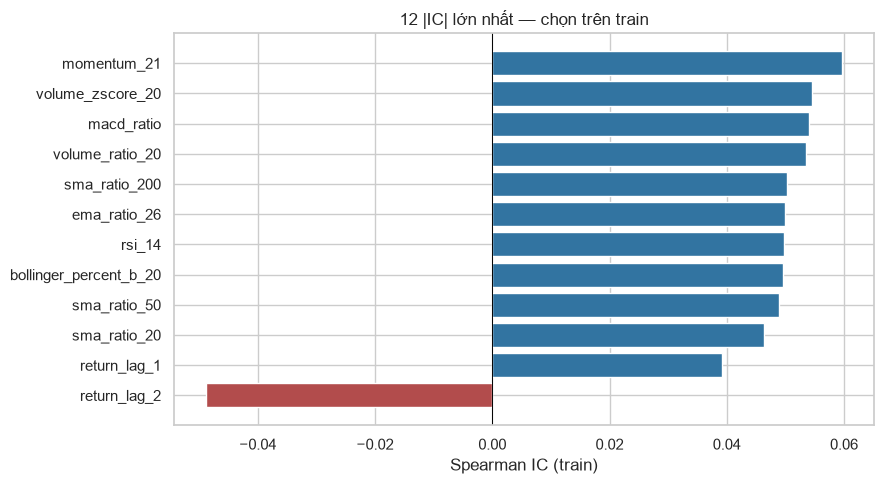

In [7]:
def association(part,col,features=names):
    rows=[]
    for f in features:
        xy=part[[f,col]].dropna(); rows.append([f,category[f],len(xy),part[[f,col]].isna().any(axis=1).sum(),xy[f].corr(xy[col],method='pearson'),xy[f].corr(xy[col],method='spearman')])
    return pd.DataFrame(rows,columns=['feature','group','n','missing','pearson','spearman']).set_index('feature')
ic=association(tr1,'forward_log_return_1'); ic['abs_ic']=ic.spearman.abs(); ic=ic.sort_values('abs_ic',ascending=False); selected=list(ic.index[:5]); display(ic.round(5))
fig,ax=plt.subplots(figsize=(9,5)); top=ic.head(12).sort_values('spearman'); ax.barh(top.index,top.spearman,color=['#b24c4c' if x<0 else '#3274a1' for x in top.spearman]); ax.axvline(0,color='black',lw=.7); ax.set(xlabel='Spearman IC (train)',title='12 |IC| lớn nhất — chọn trên train'); fig.tight_layout(); fig.savefig(figdir/'02_feature_target_ic.png',dpi=150); plt.show()
research_notes['ic']=f"Ba |IC| lớn nhất trên train: "+'; '.join(f'{f} {ic.loc[f,"spearman"]:+.4f} (n={int(ic.loc[f,"n"])})' for f in ic.index[:3])+f". Đây là thứ tự mô tả, không phải các feature đã chứng minh dự báo: {len(names)} phép thử, phụ thuộc thời gian và nhiễu chọn mẫu chưa được hiệu chỉnh. Chỉ 5 feature đầu theo train được đóng băng để đối chiếu validation. Không dùng test target."

**Diễn giải từ kết quả:** Ba |IC| lớn nhất trên train: momentum_21 +0.0597 (n=1023); volume_zscore_20 +0.0546 (n=1023); macd_ratio +0.0541 (n=1023). Đây là thứ tự mô tả, không phải các feature đã chứng minh dự báo: 26 phép thử, phụ thuộc thời gian và nhiễu chọn mẫu chưa được hiệu chỉnh. Chỉ 5 feature đầu theo train được đóng băng để đối chiếu validation. Không dùng test target.

## 8. Return và tỷ lệ lớp theo quantile

Bộ đại diện được xác định trước theo 5 nhóm: log_return, sma_ratio_20, momentum_5, volatility_21, volume_zscore_20. Chia quantile trên train; qcut bỏ cạnh trùng và báo số bin thực, không giả định số lượng bằng nhau. So sánh mean/median, tỷ lệ tăng và n chỉ để quan sát hình dạng.

,feature,bin,n,x_min,x_max,mean_return,median_return,positive_rate
0,log_return,"(-0.0735, -0.0119]",205,-0.07246,-0.01193,0.00279,0.00452,0.57561
1,log_return,"(-0.0119, -0.00233]",204,-0.01185,-0.00233,0.00083,0.00000,0.48039
2,log_return,"(-0.00233, 0.00436]",205,-0.00233,0.00436,-0.00151,-0.00119,0.42927
3,log_return,"(0.00436, 0.0159]",204,0.00437,0.01592,0.00283,0.00150,0.52451
4,log_return,"(0.0159, 0.114]",205,0.01596,0.11430,0.00133,0.00000,0.47317
5,sma_ratio_20,"(-0.179, -0.0304]",205,-0.17798,-0.03043,0.00067,0.00000,0.48293
6,sma_ratio_20,"(-0.0304, -0.00125]",204,-0.03040,-0.00131,-0.00037,0.00000,0.44608
7,sma_ratio_20,"(-0.00125, 0.0239]",205,-0.00124,0.02386,0.00067,0.00120,0.50244
8,sma_ratio_20,"(0.0239, 0.0523]",204,0.02405,0.05229,0.00225,0.00138,0.52941
9,sma_ratio_20,"(0.0523, 0.233]",205,0.05232,0.23282,0.00304,0.00206,0.52195


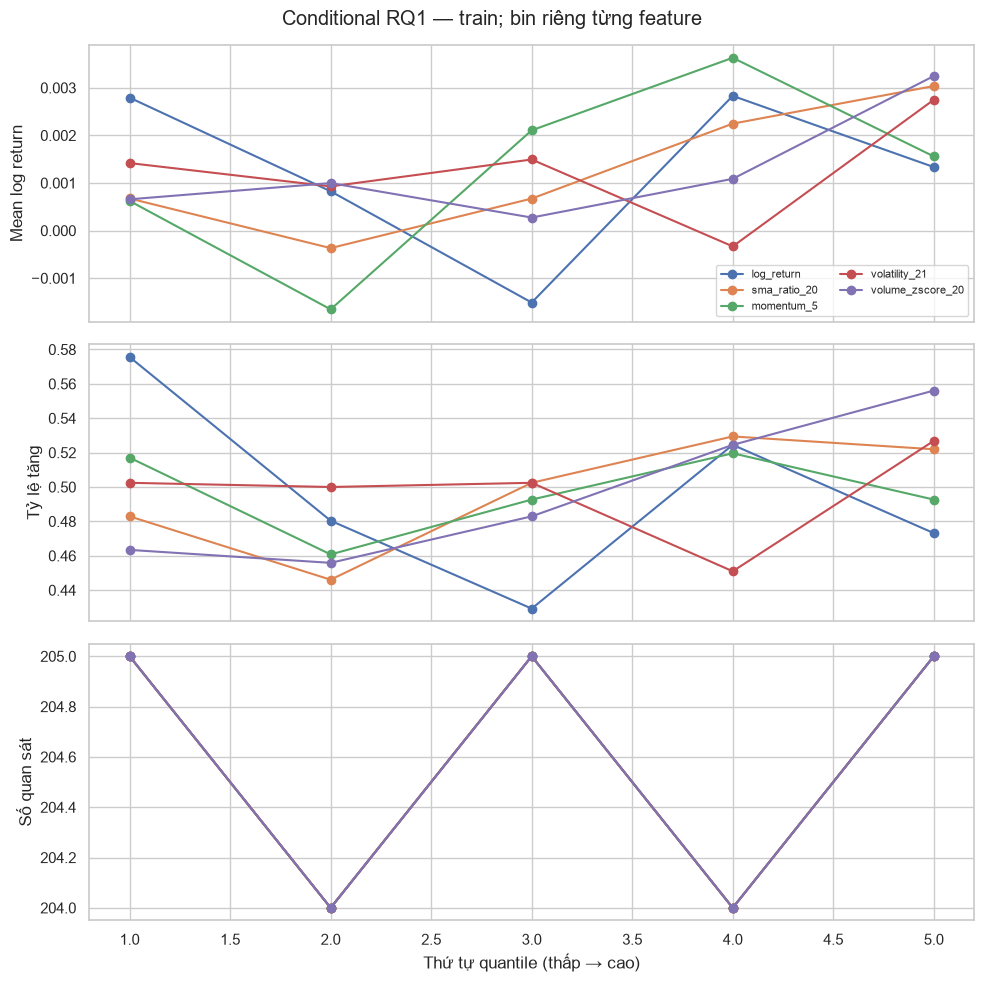

In [8]:
representatives=['log_return','sma_ratio_20','momentum_5','volatility_21','volume_zscore_20']; bins=[]
for f in representatives:
    x=tr1[[f,'forward_log_return_1','target_direction']].dropna().copy()
    try: x['bin']=pd.qcut(x[f],q=5,duplicates='drop')
    except ValueError: continue
    for b,g in x.groupby('bin',observed=True,sort=True):
        bins.append([f,str(b),len(g),g[f].min(),g[f].max(),g.forward_log_return_1.mean(),g.forward_log_return_1.median(),g.target_direction.astype(float).mean()])
conditional=pd.DataFrame(bins,columns=['feature','bin','n','x_min','x_max','mean_return','median_return','positive_rate']); display(conditional.round(5))
fig,axes=plt.subplots(3,1,figsize=(10,10),sharex=True)
for f in representatives:
    z=conditional[conditional.feature==f].reset_index(drop=True); axes[0].plot(range(1,len(z)+1),z.mean_return,marker='o',label=f); axes[1].plot(range(1,len(z)+1),z.positive_rate,marker='o'); axes[2].plot(range(1,len(z)+1),z.n,marker='o')
axes[0].set_ylabel('Mean log return'); axes[1].set_ylabel('Tỷ lệ tăng'); axes[2].set_ylabel('Số quan sát'); axes[2].set_xlabel('Thứ tự quantile (thấp → cao)'); axes[0].legend(fontsize=8,ncol=2); fig.suptitle('Conditional RQ1 — train; bin riêng từng feature'); fig.tight_layout(); fig.savefig(figdir/'02_feature_conditional_returns.png',dpi=150); plt.show()
qnotes=[]
for f in representatives:
    z=conditional[conditional.feature==f]; vals=z.mean_return.to_numpy(); mono=bool(np.all(np.diff(vals)>=0) or np.all(np.diff(vals)<=0)); qnotes.append(f'{f}: Q thấp/cao mean {vals[0]:+.5f}/{vals[-1]:+.5f}, positive {z.positive_rate.iloc[0]:.1%}/{z.positive_rate.iloc[-1]:.1%}, '+('đơn điệu' if mono else 'không đơn điệu'))
research_notes['conditional']='; '.join(qnotes)+'. Đây là khác biệt mô tả của các bin, có thể do nhiễu hoặc outlier; không suy ra quan hệ phi tuyến đã được kiểm chứng hay đặt ngưỡng giao dịch.' 

**Diễn giải từ kết quả:** log_return: Q thấp/cao mean +0.00279/+0.00133, positive 57.6%/47.3%, không đơn điệu; sma_ratio_20: Q thấp/cao mean +0.00067/+0.00304, positive 48.3%/52.2%, không đơn điệu; momentum_5: Q thấp/cao mean +0.00062/+0.00156, positive 51.7%/49.3%, không đơn điệu; volatility_21: Q thấp/cao mean +0.00142/+0.00275, positive 50.2%/52.7%, không đơn điệu; volume_zscore_20: Q thấp/cao mean +0.00066/+0.00325, positive 46.3%/55.6%, không đơn điệu. Đây là khác biệt mô tả của các bin, có thể do nhiễu hoặc outlier; không suy ra quan hệ phi tuyến đã được kiểm chứng hay đặt ngưỡng giao dịch.

## 9. Ổn định theo năm và validation

Các giả thuyết được khóa theo top 5 |IC| train trước khi xem validation. Tính IC theo năm trên train và đối chiếu với validation đã purge. 2016 có warm-up dài nên mẫu ngắn; không dùng p-value IID. Validation đã được quan sát ở đây nên không còn là tập độc lập vô hạn nếu tiếp tục điều chỉnh.

feature,macd_ratio,momentum_21,sma_ratio_200,volume_ratio_20,volume_zscore_20
year,,,,,
2016,-0.0209,-0.1303,-0.3532,-0.0455,-0.0823
2017,-0.0673,-0.0078,-0.0399,-0.0153,0.0300
2018,0.0483,0.0548,0.0482,0.1707,0.1619
2019,-0.0304,-0.0201,-0.0635,0.0726,0.0592
2020,0.0236,0.0379,0.0157,-0.0384,-0.0470


feature,macd_ratio,momentum_21,sma_ratio_200,volume_ratio_20,volume_zscore_20
year,,,,,
2016,51,51,51,51,51
2017,247,247,247,247,247
2018,244,244,244,244,244
2019,239,239,239,239,239
2020,242,242,242,242,242


,train_ic,validation_ic,train_n,validation_n,same_sign,magnitude_change
feature,,,,,,
momentum_21,0.05968,0.03226,1023,223,True,-0.02742
volume_zscore_20,0.05461,0.00968,1023,223,True,-0.04494
macd_ratio,0.05405,0.04075,1023,223,True,-0.01330
volume_ratio_20,0.05346,0.00447,1023,223,True,-0.04899
sma_ratio_200,0.05035,0.02342,1023,223,True,-0.02693


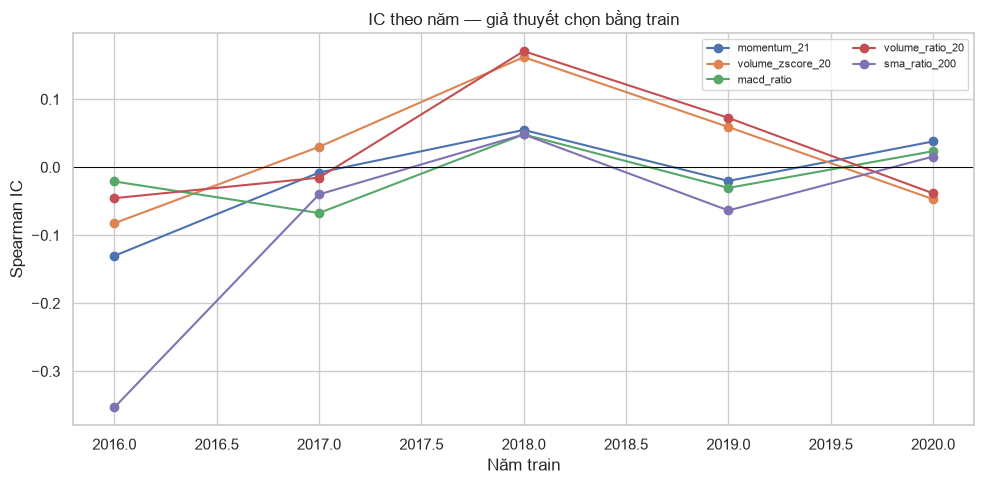

In [9]:
yearly=[]
for year,part in tr1.groupby(tr1.index.year):
    a=association(part,'forward_log_return_1',selected)
    for f in selected: yearly.append([year,f,int(a.loc[f,'n']),a.loc[f,'spearman']])
yearly=pd.DataFrame(yearly,columns=['year','feature','n','ic']); display(yearly.pivot(index='year',columns='feature',values='ic').round(4)); display(yearly.pivot(index='year',columns='feature',values='n'))
vic=association(va1,'forward_log_return_1',selected)
compare=pd.DataFrame({'train_ic':ic.loc[selected,'spearman'],'validation_ic':vic.spearman,'train_n':ic.loc[selected,'n'],'validation_n':vic.n}); compare['same_sign']=np.sign(compare.train_ic)==np.sign(compare.validation_ic); compare['magnitude_change']=compare.validation_ic.abs()-compare.train_ic.abs(); display(compare.round(5))
fig,ax=plt.subplots(figsize=(10,5));
for f in selected:
    a=yearly[yearly.feature==f]; ax.plot(a.year,a.ic,marker='o',label=f)
ax.axhline(0,color='black',lw=.7); ax.set(xlabel='Năm train',ylabel='Spearman IC',title='IC theo năm — giả thuyết chọn bằng train'); ax.legend(fontsize=8,ncol=2); fig.tight_layout(); fig.savefig(figdir/'02_feature_ic_stability.png',dpi=150); plt.show()
notes_stability=[]
for f in selected:
    z=yearly[yearly.feature==f].ic.dropna(); flips=int((np.sign(z.iloc[1:].to_numpy())!=np.sign(z.iloc[:-1].to_numpy())).sum()); notes_stability.append(f'{f}: train {compare.loc[f,"train_ic"]:+.3f}, validation {compare.loc[f,"validation_ic"]:+.3f}, đảo dấu giữa năm {flips} lần')
research_notes['stability']='; '.join(notes_stability)+'. Đổi dấu hoặc một năm chi phối là khả năng phụ thuộc chế độ; một validation năm không chứng minh hiệu quả 2022–2026.' 

**Diễn giải từ kết quả:** momentum_21: train +0.060, validation +0.032, đảo dấu giữa năm 3 lần; volume_zscore_20: train +0.055, validation +0.010, đảo dấu giữa năm 2 lần; macd_ratio: train +0.054, validation +0.041, đảo dấu giữa năm 3 lần; volume_ratio_20: train +0.053, validation +0.004, đảo dấu giữa năm 2 lần; sma_ratio_200: train +0.050, validation +0.023, đảo dấu giữa năm 3 lần. Đổi dấu hoặc một năm chi phối là khả năng phụ thuộc chế độ; một validation năm không chứng minh hiệu quả 2022–2026.

## 10. Độ nhạy outlier trên train

Trên bản sao eligible train, loại các cặp có X dưới P1 hoặc trên P99 riêng từng feature; ngưỡng xác định từ train, không ghi lại master. So sánh Pearson và Spearman trước/sau. Đây là sensitivity chứ không phê duyệt winsorization hay fit preprocessing cho Phase 3; việc loại quan sát thay đổi mẫu và không chứng minh nguyên nhân.

In [10]:
sensitivity=[]
for f in ['volume_change_1','volume_zscore_20','volume_ratio_20','log_return','volatility_21']:
    x=tr1[[f,'forward_log_return_1']].dropna(); lo,hi=x[f].quantile([.01,.99]); y=x[x[f].between(lo,hi)]
    sensitivity.append([f,lo,hi,len(x),len(y),x[f].corr(x.forward_log_return_1,method='pearson'),y[f].corr(y.forward_log_return_1,method='pearson'),x[f].corr(x.forward_log_return_1,method='spearman'),y[f].corr(y.forward_log_return_1,method='spearman')])
sens=pd.DataFrame(sensitivity,columns=['feature','p1','p99','n_full','n_trim','pearson_full','pearson_trim','ic_full','ic_trim']).set_index('feature'); sens['delta_ic']=sens.ic_trim-sens.ic_full; display(sens.round(5))
f=sens.delta_ic.abs().idxmax(); research_notes['sensitivity']=f"Trong 5 feature được kiểm tra, |Δ Spearman IC| lớn nhất sau loại hai đuôi train là {f}: {sens.loc[f,'ic_full']:+.4f} → {sens.loc[f,'ic_trim']:+.4f}, n {int(sens.loc[f,'n_full'])} → {int(sens.loc[f,'n_trim'])}. Pearson có thể thay đổi khác Spearman. Kết quả không chứng minh điểm cực đoan là lỗi; cần thử robust preprocessing fit riêng trên train trong Phase 3."

,p1,p99,n_full,n_trim,pearson_full,pearson_trim,ic_full,ic_trim,delta_ic
feature,,,,,,,,,
volume_change_1,-0.65864,2.57774,1023,1001,0.01453,0.02011,0.03641,0.03702,0.00061
volume_zscore_20,-1.57229,3.16146,1023,1001,0.04109,0.03698,0.05461,0.04431,-0.01030
volume_ratio_20,0.15337,2.62959,1023,1001,0.03125,0.03867,0.05346,0.05653,0.00307
log_return,-0.05538,0.05280,1023,1001,-0.01190,0.00945,-0.01610,-0.00947,0.00663
volatility_21,0.15550,0.57730,1023,1001,0.00808,0.00641,0.00090,0.00606,0.00515


**Diễn giải từ kết quả:** Trong 5 feature được kiểm tra, |Δ Spearman IC| lớn nhất sau loại hai đuôi train là volume_zscore_20: +0.0546 → +0.0443, n 1023 → 1001. Pearson có thể thay đổi khác Spearman. Kết quả không chứng minh điểm cực đoan là lỗi; cần thử robust preprocessing fit riêng trên train trong Phase 3.

## 11. RQ2: economic proxy bổ sung

Long-only fixed hold: tín hiệu sau Close(t), entry Open(t+1), exit Open(t+4) khi h=3; proxy tính phí, thuế và slippage theo config. Return kề nhau chồng horizon, adjusted Open chưa chắc khả thi. Không tính Sharpe, không thiết kế threshold, không coi proxy là backtest.

In [11]:
rq2ic=association(tr2,'forward_trade_net_return_proxy'); rq2ic['abs_ic']=rq2ic.spearman.abs(); rq2ic=rq2ic.sort_values('abs_ic',ascending=False); display(rq2ic.round(5))
comparison_rq=pd.DataFrame({'RQ1_train_IC':ic.spearman,'RQ2_train_IC':rq2ic.spearman}).loc[selected]; display(comparison_rq.round(4))
proxy_means=pd.DataFrame({'gross_mean':[tr2.forward_trade_gross_return.mean(),va2.forward_trade_gross_return.mean()],'net_mean':[tr2.forward_trade_net_return_proxy.mean(),va2.forward_trade_net_return_proxy.mean()],'net_median':[tr2.forward_trade_net_return_proxy.median(),va2.forward_trade_net_return_proxy.median()]},index=['Train','Validation']); display(proxy_means)
f=rq2ic.index[0]; research_notes['rq2']=f"Train net proxy trung bình {proxy_means.loc['Train','net_mean']:+.5f}, median {proxy_means.loc['Train','net_median']:+.5f}; validation trung bình {proxy_means.loc['Validation','net_mean']:+.5f}. |RQ2 IC| lớn nhất mô tả thuộc {f}: {rq2ic.loc[f,'spearman']:+.4f}; không dùng ranking này để xây chiến lược. Close–Close một phiên và Open–Open nhiều phiên có rủi ro, chi phí và horizon khác; return chồng lấn không phải PnL thực hiện."

,group,n,missing,pearson,spearman,abs_ic
feature,,,,,,
sma_ratio_200,Trend,1020,0,0.06354,0.06637,0.06637
momentum_21,Momentum,1020,0,0.07107,0.06431,0.06431
macd_ratio,Trend,1020,0,0.05430,0.05869,0.05869
bollinger_percent_b_20,Volatility,1020,0,0.06733,0.05567,0.05567
ema_ratio_26,Trend,1020,0,0.05449,0.05506,0.05506
sma_ratio_20,Trend,1020,0,0.05499,0.05453,0.05453
rsi_14,Momentum,1020,0,0.06892,0.05436,0.05436
sma_ratio_50,Trend,1020,0,0.05148,0.04975,0.04975
return_lag_10,Returns,1020,0,0.03071,0.04063,0.04063


,RQ1_train_IC,RQ2_train_IC
feature,,
momentum_21,0.0597,0.0643
volume_zscore_20,0.0546,0.0120
macd_ratio,0.0541,0.0587
volume_ratio_20,0.0535,0.0152
sma_ratio_200,0.0503,0.0664


,gross_mean,net_mean,net_median
Train,0.004530,-0.000482,-0.001183
Validation,0.006206,0.001185,0.003439


**Diễn giải từ kết quả:** Train net proxy trung bình -0.00048, median -0.00118; validation trung bình +0.00119. |RQ2 IC| lớn nhất mô tả thuộc sma_ratio_200: +0.0664; không dùng ranking này để xây chiến lược. Close–Close một phiên và Open–Open nhiều phiên có rủi ro, chi phí và horizon khác; return chồng lấn không phải PnL thực hiện.

## 12. Bảng tổng hợp và hướng Phase 3

Giữ baseline 26 feature. IC validation chỉ hiện cho 5 giả thuyết đã khóa trên train. Redundancy và sensitivity là ghi chú mô tả; chưa thực hiện lựa chọn feature.

In [12]:
summary_rows=[]
for f in names:
    maxcorr=pear.loc[f].drop(f).abs().max(); other=pear.loc[f].drop(f).abs().idxmax(); st=stats.loc[f]; vi=compare.loc[f,'validation_ic'] if f in compare.index else np.nan
    flips=(int((np.sign(yearly.loc[yearly.feature==f,'ic'].iloc[1:].to_numpy())!=np.sign(yearly.loc[yearly.feature==f,'ic'].iloc[:-1].to_numpy())).sum()) if f in selected else None)
    summary_rows.append([f,category[f],f"skew={st['skew']:.2f}; min/max={st['min']:.3g}/{st['max']:.3g}",f'{other}: |r|={maxcorr:.2f}',ic.loc[f,'spearman'],vi, f'{flips} lần đổi dấu năm' if flips is not None else 'Chưa kiểm tra giả thuyết',f"ΔIC={sens.loc[f,'delta_ic']:+.3f}" if f in sens.index else 'Chưa kiểm tra riêng','Mô tả; chưa chứng minh alpha','Kiểm tra trong baseline Phase 3'])
feature_summary=pd.DataFrame(summary_rows,columns=['feature','group','distribution','redundancy','train_ic','validation_ic','yearly','outlier_sensitivity','interpretation','phase3']); display(feature_summary)
research_notes['summary']=f"Baseline giữ đủ {len(names)} features. Đã kiểm tra validation cho {len(selected)} giả thuyết chọn từ train, {int(compare.same_sign.sum())}/{len(selected)} giữ cùng dấu; đó không phải kết luận về significance hay test. Cần train-only scaling, robust preprocessing có kiểm soát, walk-forward, purge theo label, calibration xác suất và so sánh baseline; kiểm tra nguồn volume và giá adjusted trước khi suy diễn kết quả."

,feature,group,distribution,redundancy,train_ic,validation_ic,yearly,outlier_sensitivity,interpretation,phase3
0,log_return,Returns,skew=0.04; min/max=-0.0725/0.114,sma_ratio_10: |r|=0.54,-0.016102,NaN,Chưa kiểm tra giả thuyết,ΔIC=+0.007,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
1,return_lag_1,Returns,skew=0.04; min/max=-0.0725/0.114,sma_ratio_10: |r|=0.47,0.039146,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
2,return_lag_2,Returns,skew=0.04; min/max=-0.0725/0.114,momentum_5: |r|=0.47,-0.048846,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
3,return_lag_3,Returns,skew=0.04; min/max=-0.0725/0.114,momentum_5: |r|=0.43,0.020292,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
4,return_lag_5,Returns,skew=0.04; min/max=-0.0725/0.114,momentum_10: |r|=0.33,-0.012039,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
5,return_lag_10,Returns,skew=0.04; min/max=-0.0725/0.114,macd_ratio: |r|=0.25,0.028683,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
6,return_lag_21,Returns,skew=0.04; min/max=-0.0725/0.114,sma_ratio_50: |r|=0.18,0.022519,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
7,sma_ratio_10,Trend,skew=0.04; min/max=-0.113/0.147,ema_ratio_12: |r|=0.97,0.032220,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
8,sma_ratio_20,Trend,skew=0.07; min/max=-0.178/0.233,ema_ratio_26: |r|=0.96,0.046417,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
9,sma_ratio_50,Trend,skew=0.20; min/max=-0.278/0.417,macd_ratio: |r|=0.96,0.048880,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3


**Diễn giải từ kết quả:** Baseline giữ đủ 26 features. Đã kiểm tra validation cho 5 giả thuyết chọn từ train, 5/5 giữ cùng dấu; đó không phải kết luận về significance hay test. Cần train-only scaling, robust preprocessing có kiểm soát, walk-forward, purge theo label, calibration xác suất và so sánh baseline; kiểm tra nguồn volume và giá adjusted trước khi suy diễn kết quả.

## 13. Kết luận và giới hạn

Một mã HPG và một giai đoạn validation không đủ để suy rộng. Nhiều phép thử, chuỗi phụ thuộc, non-stationarity, điều chỉnh giá hồi tố, corporate actions, volume bất thường và giả định phí tạo rủi ro. Validation đã được dùng để xem giả thuyết; tiếp tục chỉnh theo kết quả sẽ làm nó kém độc lập. Phase 3 cần giữ test kín, đánh giá walk-forward có purge và đối chiếu baseline. Không kết luận causal effect, alpha hay profitability từ IC.